# 08 — Comparación de modelos y evaluación final

**Elaborado por:** Santiago Cardozo

## Objetivo

Cerrar el recorrido en cuatro pasos:

1. **Comparar** los tres modelos (cuadernillos 05, 06 y 07) entre sí y contra líneas base simples, en validación (2025).
2. **Elegir** uno y **ajustar** su configuración.
3. **Evaluarlo una sola vez** en el conjunto de prueba (2026), que no se ha usado en ningún momento del proyecto.
4. **Entender** el modelo final: dónde acierta, dónde falla y qué variables usa.

El cuadernillo termina con las conclusiones generales del proyecto.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline

from src.config import PROCESSED_DIR, TABLES_DIR, load_config
from src.evaluation import accuracy_interval, evaluate, temporal_split
from src.plotting import set_style, save_fig

set_style()
config = load_config()
FEATURES, TARGET, SEED = config["features"], config["target"], config["seed"]
MIN_HISTORY = config["min_train_history"]

dataset = pd.read_csv(PROCESSED_DIR / "dataset.csv")
train, val, test = temporal_split(dataset, config["split"])
y_val = val[TARGET]

## 1. Líneas base y comparación en validación

Un número como "57 % de exactitud" no significa nada solo: hay que saber qué se consigue **sin
modelo**. Por eso se fijan tres referencias mínimas (*líneas base*):

- **Clase mayoritaria:** predecir siempre la proporción de victorias de Team A en entrenamiento (≈ 50 %).
- **Regla del winrate:** gana el equipo con mejor winrate histórico (la regla del cuadernillo 02).
  Como da un veredicto y no una probabilidad, solo se le puede medir la exactitud.
- **Logística de una variable:** una regresión logística que solo usa `diff_winrate`. Es la
  versión "con probabilidades" de la regla anterior.

A esas tres filas se les agregan los resultados que guardó cada cuadernillo de modelo.

In [2]:
results = {}
results["Base: clase mayoritaria"] = evaluate(y_val, np.full(len(val), train[TARGET].mean()))

rule_proba = np.select([val["diff_winrate"] > 0, val["diff_winrate"] < 0], [1.0, 0.0], default=0.5)
rule_decided = rule_proba != 0.5
results["Base: regla del winrate"] = {
    "accuracy": ((rule_proba > 0.5) == (y_val == 1))[rule_decided].mean(), "roc_auc": np.nan, "log_loss": np.nan}

one_variable = make_pipeline(SimpleImputer(strategy="median"), LogisticRegression())
one_variable.fit(train[["diff_winrate"]], train[TARGET])
results["Base: logística de 1 variable"] = evaluate(y_val, one_variable.predict_proba(val[["diff_winrate"]])[:, 1])

comparison = pd.concat([
    pd.DataFrame(results).T,
    pd.read_csv(TABLES_DIR / "05_resultados_regresion_logistica.csv", index_col=0),
    pd.read_csv(TABLES_DIR / "06_resultados_random_forest.csv", index_col=0),
    pd.read_csv(TABLES_DIR / "07_resultados_gradient_boosting.csv", index_col=0),
])
comparison.to_csv(TABLES_DIR / "08_comparacion_modelos.csv")
comparison.round(4)

,accuracy,roc_auc,log_loss
Base: clase mayoritaria,0.4976,0.5000,0.6932
Base: regla del winrate,0.5778,NaN,NaN
Base: logística de 1 variable,0.5692,0.5920,0.6801
Regresión logística,0.5723,0.5986,0.6878
Random Forest,0.5637,0.5810,0.6884
Gradient Boosting,0.5755,0.5974,0.6802


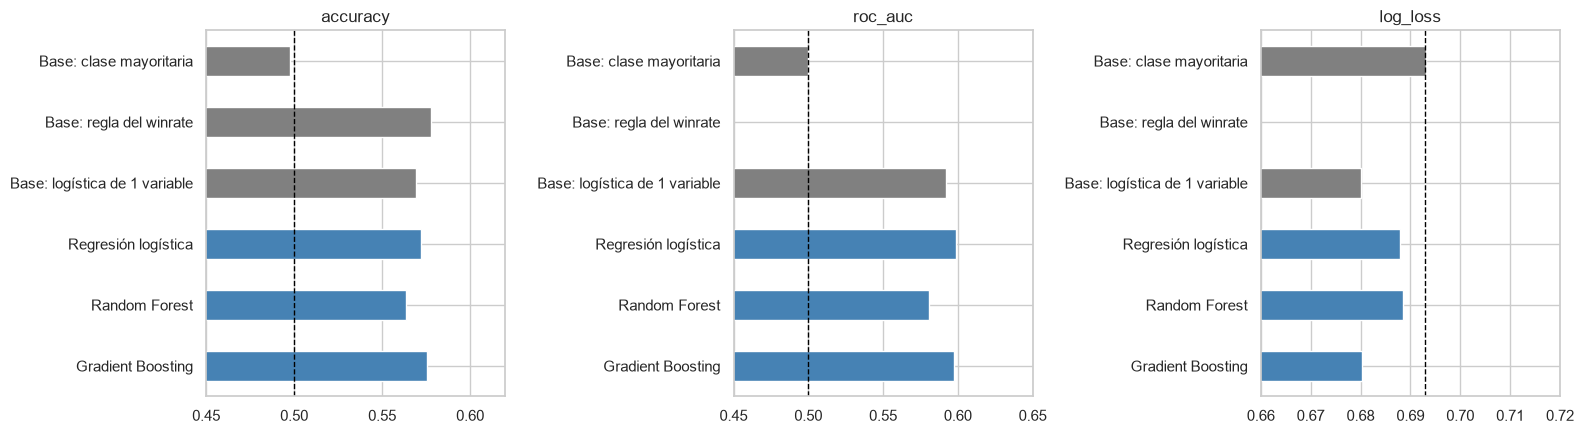

Base: logística de 1 variable  exactitud 0.569  (IC 95 %: 0.542 – 0.596)
Regresión logística            exactitud 0.572  (IC 95 %: 0.545 – 0.600)
Random Forest                  exactitud 0.564  (IC 95 %: 0.536 – 0.591)
Gradient Boosting              exactitud 0.575  (IC 95 %: 0.548 – 0.603)


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colors = ["grey" if name.startswith("Base") else "steelblue" for name in comparison.index]
for ax, (metric, reference, limits) in zip(axes, [("accuracy", 0.5, (0.45, 0.62)),
                                                   ("roc_auc", 0.5, (0.45, 0.65)),
                                                   ("log_loss", 0.693, (0.66, 0.72))]):
    comparison[metric].plot.barh(ax=ax, color=colors)
    ax.axvline(reference, color="black", linestyle="--", linewidth=1)
    ax.set(title=metric, xlim=limits)
    ax.invert_yaxis()
plt.tight_layout()
save_fig("08_comparacion_modelos")
plt.show()

n = len(val)
for name in comparison.index[2:]:
    low, high = accuracy_interval(comparison.loc[name, "accuracy"], n)
    print(f"{name:<30} exactitud {comparison.loc[name, 'accuracy']:.3f}  (IC 95 %: {low:.3f} – {high:.3f})")

**Por qué este gráfico:** la tabla tiene 6 métodos y 3 métricas; en barras se ve de inmediato quién está por delante en cada métrica y, sobre todo, **qué tan cerca** están unos de otros.

**Cómo se lee:** hay un panel por métrica. Cada barra es un método: en gris las líneas base y en azul los modelos. La línea punteada es la referencia de "no saber nada" (0.5 en exactitud y ROC-AUC; 0.693 en log loss). En exactitud y ROC-AUC, **más a la derecha es mejor**; en log loss es al revés, **más a la izquierda es mejor**. Los ejes están recortados para que las diferencias se noten: son más pequeñas de lo que parecen. La regla del winrate no tiene barra en ROC-AUC ni en log loss porque no da probabilidades.

**Qué muestra:** todos superan al azar, pero los tres modelos quedan muy cerca entre sí y de las líneas base. El Gradient Boosting tiene el menor log loss de los tres modelos y la mayor exactitud; aun así empata en log loss con la logística de una sola variable.

**¿Qué tan seguras son estas diferencias?** La validación tiene 1 272 mapas. Los intervalos de
confianza impresos arriba miden unos ±2.7 puntos y **se solapan** entre todos los modelos:
diferencias de uno o dos puntos de exactitud están dentro del margen de error.

**Decisión:** el criterio fijado de antemano es el **menor log loss en validación**. Con ese
criterio pasa a la etapa final el **Gradient Boosting** (0.680), que además tiene la mayor
exactitud. Hay que decirlo con claridad: ningún modelo supera de forma convincente a las
líneas base.

## 2. Datos para el ajuste

Hasta ahora la validación (2025) sirvió para comparar modelos. Esa decisión ya está tomada,
así que 2025 puede sumarse al entrenamiento: es el año más parecido al que se va a predecir.

Se aplica el mismo filtro (ambos equipos con 30 o más mapas previos) y se ordenan los mapas
cronológicamente, porque la validación cruzada que sigue depende del orden.

In [4]:
development = pd.concat([train, val])
development = (development[development["min_maps_played"] >= MIN_HISTORY]
               .sort_values(["stage_block", "match_id", "game_id"]))
X_dev, y_dev = development[FEATURES], development[TARGET]
print(f"Mapas para ajuste y entrenamiento final: {len(development)}")
development["year"].value_counts().sort_index().to_frame("maps").T

Mapas para ajuste y entrenamiento final: 6188


year,2021,2022,2023,2024,2025
maps,1608,2017,585,896,1082


## 3. Ajuste de la configuración (hiperparámetros)

Los **hiperparámetros** son las perillas del modelo que no se aprenden de los datos, sino que
se eligen antes de entrenar. En el cuadernillo 07 se fijaron a mano; aquí se busca la mejor
combinación de forma sistemática.

| Hiperparámetro | Qué controla |
|---|---|
| `learning_rate` | Cuánto corrige cada árbol; valores bajos aprenden despacio y generalizan mejor |
| `max_iter` | Número de árboles |
| `max_depth` | Profundidad de cada árbol: cuántas variables puede combinar |
| `min_samples_leaf` | Mapas mínimos por hoja; valores altos evitan memorizar casos aislados |
| `l2_regularization` | Penalización que encoge las predicciones de cada hoja |

**Cómo se valida cada combinación.** Con validación cruzada *temporal* (`TimeSeriesSplit`):
los datos, ya ordenados en el tiempo, se cortan en bloques consecutivos; cada combinación se
entrena con los bloques anteriores y se mide en el siguiente. Es la misma idea de la partición
por año, repetida cinco veces:

```
Corte 1:  [entrena][valida]
Corte 2:  [   entrena   ][valida]
Corte 3:  [      entrena      ][valida]   …
```

**Cómo se busca.** Se prueban 40 combinaciones elegidas al azar y se queda la de menor log
loss promedio en los cinco cortes.

In [5]:
cv = TimeSeriesSplit(n_splits=5)
search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=SEED),
    param_distributions={
        "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
        "max_iter": [50, 100, 200, 300],
        "max_depth": [2, 3, 4],
        "min_samples_leaf": [20, 50, 100, 200],
        "l2_regularization": [0, 0.1, 1, 10],
    },
    n_iter=40, cv=cv, scoring="neg_log_loss", random_state=SEED, n_jobs=-1,
)
search.fit(X_dev, y_dev)
print("Mejor combinación:", search.best_params_)
print(f"Log loss en validación cruzada: {-search.best_score_:.4f}")

cv_results = pd.DataFrame(search.cv_results_)
cv_results["log_loss"] = -cv_results["mean_test_score"]
cv_table = cv_results.sort_values("log_loss")[[c for c in cv_results.columns if c.startswith("param_")] + ["log_loss"]]
cv_table.to_csv(TABLES_DIR / "08_busqueda_hiperparametros.csv", index=False)
pd.concat([cv_table.head(3), cv_table.tail(3)]).round(4)

Mejor combinación: {'min_samples_leaf': 200, 'max_iter': 50, 'max_depth': 3, 'learning_rate': 0.02, 'l2_regularization': 0}
Log loss en validación cruzada: 0.6825


,param_min_samples_leaf,param_max_iter,param_max_depth,param_learning_rate,param_l2_regularization,log_loss
11,200,50,3,0.02,0.0,0.6825
25,200,100,3,0.01,0.0,0.6826
18,50,50,3,0.02,10.0,0.6829
12,100,200,3,0.10,0.0,0.7099
35,20,100,4,0.10,1.0,0.7120
1,50,300,4,0.10,0.1,0.7507


Las mejores combinaciones son las más conservadoras: árboles poco profundos, tasa de
aprendizaje baja y hojas grandes. Las peores son las de mayor capacidad. Es coherente con la
curva de log loss del cuadernillo 07: con poca señal, la complejidad se convierte en sobreajuste.

`RandomizedSearchCV` ya reentrenó la mejor combinación con todos los datos de desarrollo
(2021–2025 filtrados). **Ese es el modelo final.**

In [6]:
final_model = search.best_estimator_
final_model

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.02
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",50
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",3
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",200
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values.

## 4. Evaluación en el conjunto de prueba (2026)

Este es el único momento del proyecto en que se usan los 886 mapas de 2026. Ninguna decisión
anterior —variables, filtro de entrenamiento, modelo, hiperparámetros— los vio. El resultado
que salga aquí es el que se reporta, sin volver atrás a retocar nada.

Se evalúan también las líneas base, reentrenadas con los mismos datos de desarrollo, porque
el número del modelo solo significa algo en comparación con ellas.

In [7]:
X_test, y_test = test[FEATURES], test[TARGET]
final_proba = final_model.predict_proba(X_test)[:, 1]

results = {}
results["Base: clase mayoritaria"] = evaluate(y_test, np.full(len(test), y_dev.mean()))

rule_proba = np.select([test["diff_winrate"] > 0, test["diff_winrate"] < 0], [1.0, 0.0], default=0.5)
rule_decided = rule_proba != 0.5
results["Base: regla del winrate"] = {
    "accuracy": ((rule_proba > 0.5) == (y_test == 1))[rule_decided].mean(), "roc_auc": np.nan, "log_loss": np.nan}

one_variable = make_pipeline(SimpleImputer(strategy="median"), LogisticRegression())
one_variable.fit(development[["diff_winrate"]], y_dev)
one_variable_proba = one_variable.predict_proba(test[["diff_winrate"]])[:, 1]
results["Base: logística de 1 variable"] = evaluate(y_test, one_variable_proba)

results["Modelo final: Gradient Boosting ajustado"] = evaluate(y_test, final_proba)

final_results = pd.DataFrame(results).T
final_results.to_csv(TABLES_DIR / "08_resultados_finales.csv")
final_results.round(4)

,accuracy,roc_auc,log_loss
Base: clase mayoritaria,0.4966,0.5000,0.6932
Base: regla del winrate,0.5603,NaN,NaN
Base: logística de 1 variable,0.5474,0.5869,0.6798
Modelo final: Gradient Boosting ajustado,0.5711,0.6061,0.6796


### ¿Qué tan firme es el resultado? Intervalos de confianza

El 57.1 % se midió sobre 886 mapas. Si se hubiera medido sobre otros 886 mapas parecidos,
habría salido un número algo distinto, por puro azar. El **intervalo de confianza del 95 %**
dice entre qué valores estaría razonablemente la exactitud "verdadera" del modelo:

$$\text{exactitud} \pm 1.96 \times \sqrt{\frac{\text{exactitud} \times (1 - \text{exactitud})}{n}}$$

Cuantos más mapas (*n*), más angosto el intervalo.

In [8]:
rows = {}
for name, n in [("Base: regla del winrate", rule_decided.sum()),
                ("Base: logística de 1 variable", len(test)),
                ("Modelo final: Gradient Boosting ajustado", len(test))]:
    accuracy = final_results.loc[name, "accuracy"]
    low, high = accuracy_interval(accuracy, n)
    rows[name] = {"exactitud": accuracy, "IC 95 % inferior": low, "IC 95 % superior": high, "mapas": n}
pd.DataFrame(rows).T.round(3).astype({"mapas": int})

,exactitud,IC 95 % inferior,IC 95 % superior,mapas
Base: regla del winrate,0.560,0.527,0.594,837
Base: logística de 1 variable,0.547,0.515,0.580,886
Modelo final: Gradient Boosting ajustado,0.571,0.539,0.604,886


Lectura de los resultados en prueba:

- **Exactitud: 57.1 %** (IC 95 %: 53.9 %–60.4 %). El intervalo queda completo por encima del
  50 %: el modelo predice mejor que el azar, sin duda razonable.
- **Frente a las líneas base en exactitud:** queda por encima de la regla del winrate (56.0 %)
  y de la logística de una variable (54.7 %), pero los intervalos se solapan: con 886 mapas no
  se puede asegurar que esa ventaja no sea suerte.
- **Frente a las líneas base en log loss:** empate (0.6796 contra 0.6798). Las probabilidades
  del modelo no son mejores que las de una logística con una sola variable.
- **ROC-AUC: 0.606**, frente a 0.587 de la línea base: el modelo ordena algo mejor los mapas.

El resultado en prueba es muy parecido al de validación (57.5 % y log loss 0.680 en 2025), lo
que indica que el procedimiento no se sobreajustó a la validación.

## 5. Aciertos y errores: matriz de confusión y curva ROC

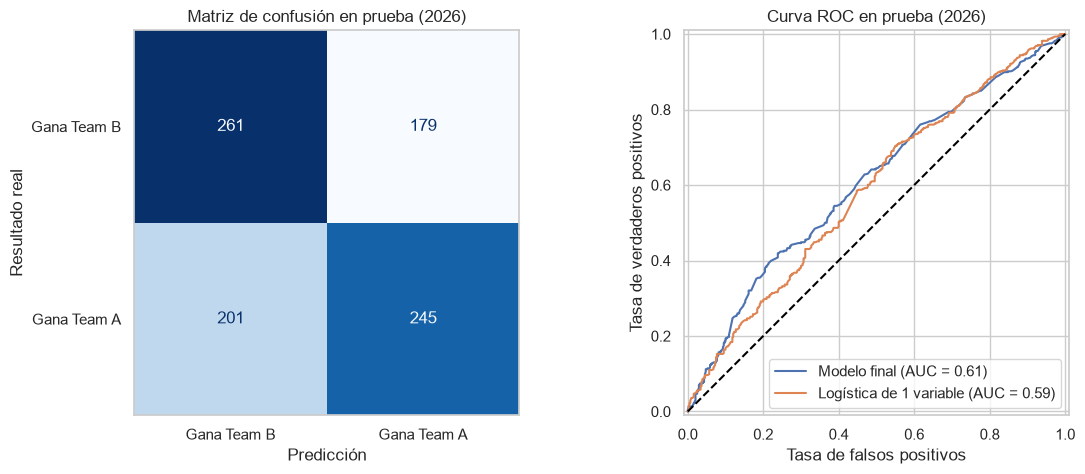

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, final_proba > 0.5, ax=axes[0], cmap="Blues", colorbar=False,
                                        display_labels=["Gana Team B", "Gana Team A"])
axes[0].set(title="Matriz de confusión en prueba (2026)", xlabel="Predicción", ylabel="Resultado real")
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, final_proba, name="Modelo final", ax=axes[1])
RocCurveDisplay.from_predictions(y_test, one_variable_proba, name="Logística de 1 variable", ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="black")
axes[1].set(title="Curva ROC en prueba (2026)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
save_fig("08_matriz_confusion_y_roc")
plt.show()

**Por qué este gráfico:** la exactitud resume todo en un número. La matriz de confusión muestra *qué tipo* de aciertos y errores hay detrás de él, y la curva ROC muestra el comportamiento del modelo sin depender del corte de 50 %. Son los dos gráficos estándar para evaluar un clasificador.

**Cómo se lee — matriz de confusión (izquierda):** las filas son lo que realmente pasó y las columnas lo que el modelo predijo. Las dos casillas de la diagonal (arriba-izquierda y abajo-derecha) son los **aciertos**; las otras dos, los **errores**. La exactitud es la suma de la diagonal dividida entre el total de mapas.

**Cómo se lee — curva ROC (derecha):** cada punto de la curva corresponde a un corte distinto de probabilidad para decir "gana Team A". El eje vertical es la proporción de victorias de A que el modelo detecta; el horizontal, la proporción de derrotas de A que marca por error como victorias. La diagonal punteada es adivinar al azar. Cuanto más se arquea la curva hacia la esquina superior izquierda, mejor; el **AUC** de la leyenda es el área bajo la curva (0.5 = azar, 1 = perfecto).

**Qué muestra:** los aciertos y los errores se reparten de forma similar entre las dos clases: el modelo no tiene preferencia por Team A ni por Team B, como debe ser después del intercambio aleatorio del cuadernillo 03. Las dos curvas ROC quedan por encima de la diagonal, pero no muy lejos: el modelo ordena mejor que el azar, con una ventaja modesta, y la del modelo final va ligeramente por encima de la línea base.

## 6. ¿Qué variables usa el modelo final?

El Gradient Boosting no tiene coeficientes ni una importancia "de fábrica" como el Random
Forest. Se usa la **importancia por permutación**: se desordenan al azar los valores de una
variable (así pierde su relación con el resultado) y se mide cuánto empeora el log loss. Si
desordenarla no cambia nada, el modelo no la necesitaba.

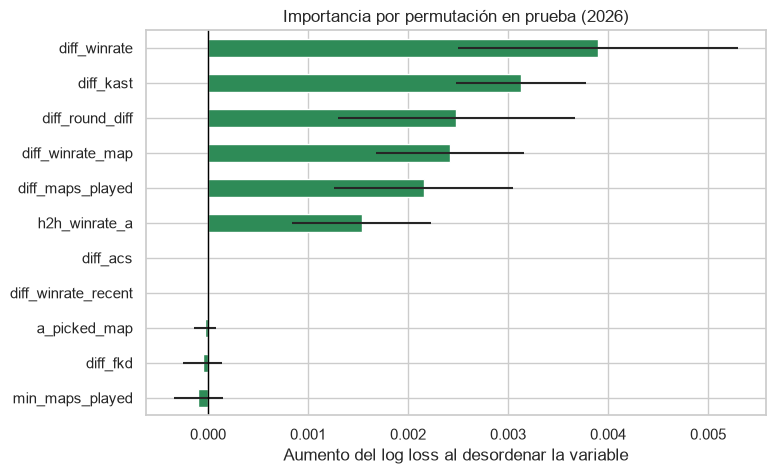

In [10]:
importance = permutation_importance(final_model, X_test, y_test, scoring="neg_log_loss",
                                    n_repeats=50, random_state=SEED)
importance = pd.DataFrame({"mean": importance.importances_mean, "std": importance.importances_std},
                          index=FEATURES).sort_values("mean")
importance.to_csv(TABLES_DIR / "08_importancia_variables.csv")
ax = importance["mean"].plot.barh(xerr=importance["std"], color="seagreen", figsize=(8, 5))
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Importancia por permutación en prueba (2026)", xlabel="Aumento del log loss al desordenar la variable")
save_fig("08_importancia_variables")
plt.show()

**Por qué este gráfico:** responde "¿en qué se fija el modelo?". La importancia por permutación sirve para cualquier modelo y se mide sobre datos que el modelo no vio, así que refleja lo que de verdad le sirve para predecir.

**Cómo se lee:** cada barra es una variable; su largo es cuánto **empeora** el log loss cuando esa variable se desordena. Barra larga = el modelo depende de ella. Barra en cero = el modelo no la usa. La rayita negra indica cuánto varía esa medida entre las 50 repeticiones: si la rayita cruza el cero, la importancia no es distinguible de nada.

**Qué muestra:** el modelo se apoya en seis variables: el winrate histórico (`diff_winrate`), la consistencia individual (`diff_kast`), el margen de rondas (`diff_round_diff`), el winrate en el mapa concreto (`diff_winrate_map`), la experiencia (`diff_maps_played`) y los enfrentamientos directos (`h2h_winrate_a`). Las otras cinco tienen importancia nula: con solo 50 árboles pequeños el modelo no llegó a usarlas. Todas las importancias son pequeñas (milésimas de log loss): ninguna variable es decisiva por sí sola.

## 7. ¿Acierta más cuando está más seguro?

Si las probabilidades significan algo, el modelo debería acertar más cuando está más seguro.

In [11]:
analysis = test.assign(proba=final_proba, correct=(final_proba > 0.5) == (y_test == 1))
analysis["confidence"] = (analysis["proba"] - 0.5).abs() + 0.5
print(f"Rango de probabilidades: {final_proba.min():.2f} – {final_proba.max():.2f}")
(analysis.groupby(pd.cut(analysis["confidence"], [0.5, 0.55, 0.6, 0.65, 1.0], include_lowest=True), observed=True)
 ["correct"].agg(accuracy="mean", maps="size").round(3))

Rango de probabilidades: 0.37 – 0.65


,accuracy,maps
confidence,,
"(0.499, 0.55]",0.532,592
"(0.55, 0.6]",0.648,250
"(0.6, 0.65]",0.659,44


El modelo es **prudente**: nunca da menos de 37 % ni más de 65 % a un equipo. Y sus
probabilidades tienen contenido real: en los dos tercios de los mapas donde apenas se inclina
por un equipo (confianza menor a 55 %) acierta el 53 %, prácticamente una moneda, y el modelo
lo "sabe". En el tercio restante, donde ve un favorito, acierta cerca del 65 %.

## Conclusiones

### Del cuadernillo

1. **Comparación en validación (2025):** los tres modelos quedan muy cerca entre sí y de las
   líneas base. Con el criterio fijado de antemano (menor log loss) se eligió el Gradient Boosting.
2. **Modelo final:** Gradient Boosting con 50 árboles de profundidad 3, tasa de aprendizaje
   0.02 y hojas de al menos 200 mapas, entrenado con 6 188 mapas de 2021–2025 en los que ambos
   equipos tenían 30 o más mapas previos. El ajuste confirmó que menos es más: las mejores
   configuraciones son las más simples.
3. **Resultado en prueba (886 mapas de 2026, usados una sola vez):**

   | Modelo | Exactitud | ROC-AUC | Log loss |
   |---|---|---|---|
   | Base: clase mayoritaria | 0.497 | 0.500 | 0.693 |
   | Base: regla del winrate | 0.560 | — | — |
   | Base: logística de 1 variable | 0.547 | 0.587 | 0.680 |
   | **Modelo final** | **0.571** | **0.606** | **0.680** |

4. **Qué significa:** el modelo acierta el ganador del 57.1 % de los mapas (IC 95 %:
   53.9 %–60.4 %), claramente mejor que el azar. Frente a las reglas simples queda algo por
   encima en exactitud y en capacidad de ordenar, pero dentro del margen de error; en calidad
   de probabilidades empata con una logística de una sola variable.
5. **Sus probabilidades son honestas:** van de 37 % a 65 %, y cuando el modelo ve un favorito
   (un tercio de los mapas) acierta cerca del 65 %.

### Del proyecto

**Objetivo:** predecir qué equipo gana un mapa de VCT antes de que se juegue.
**Respuesta:** se puede, con una ventaja modesta. El resultado de un mapa entre equipos
profesionales es difícil de anticipar con estadísticas históricas: el 28 % de los mapas se
decide por tres rondas o menos, y los equipos de las ligas actuales son parejos.

Lo que el recorrido deja, paso a paso:

- **00–01:** el dataset no trae fechas y los IDs no ordenan los partidos dentro de una etapa.
  De ahí salió la regla que protege todo el proyecto: el historial solo usa etapas anteriores.
- **02:** Team A gana más por cómo la web ordena a los equipos, no por jugar mejor. Se
  corrigió intercambiando equipos al azar.
- **03:** las estadísticas del propio mapa "predicen" con 94 % de acierto porque son
  consecuencia del resultado. Las variables históricas, sin fuga, dan una señal real pero pequeña.
- **04:** los datos se separan por año (entrenamiento, validación y prueba) y 11 variables bastan.
- **05–07:** tres modelos, uno por cuadernillo. Entrenar con partidos que no se parecen a los
  que se quiere predecir arruina las probabilidades, y la configuración importa más que el modelo.
- **08:** 57.1 % de exactitud en un año completo que el modelo nunca vio.

**Limitaciones**

- **Sin fechas:** el orden temporal se aproxima con IDs y por etapas. Dentro de una etapa
  larga (una fase de grupos de varias semanas) el modelo no ve los resultados más recientes.
- **Historial por nombre de equipo:** si un equipo cambia de jugadores, conserva su historial;
  si cambia de nombre, lo pierde.
- **Datos de entrenamiento escasos para el problema real:** de 27 368 mapas, solo 6 188
  corresponden a cruces entre equipos con historial.
- **2026 es una temporada parcial** (886 mapas): los intervalos de confianza son anchos.
- **No se usa la composición de agentes ni el lado inicial**, que se conocen justo antes del mapa.

**Mejoras posibles**

- Construir el historial **por jugador** y agregarlo según la alineación de cada partido.
- Ponderar más los mapas recientes en lugar de promedios de toda la historia.
- Conseguir las fechas reales de los partidos para usar también el historial dentro de la etapa.
- Incorporar la composición de agentes de cada equipo en el mapa.

Con lo que se tiene hasta ahora, el plan actual queda completo: un modelo reproducible,
evaluado sin fuga de datos y con un resultado que se puede defender tal cual es.